# Team Members

|  **Student** |  **Name**     | **Entry Number** |
|:--------------:|:---------------:|:-------------------:|
| **1**          | ARPIT GOYAL     | 2023MT10202         |
| **2**          | HARSHAL LASOD   | 2023MT11076         |


---

# MTL782 Assignment 1: Abalone Age Prediction

## Objective
Predict the age of abalone (target variable: **Rings + 1.5**) using various regression techniques.

### Tasks:
1. **Task 1:** Load the Abalone dataset from UCI ML Repository and inspect properties (missing values, variable types)
2. **Task 2:**
   - (i) Multivariate Regression using QR Factorization (Closed-form solution)
   - (ii) SGD for Linear Regression
   - (iii) SGD with Ridge Regression (L2 regularization)
   - (iv) SGD with LASSO Regression (L1 regularization)
   - (v) Comparison with `sklearn` **LinearRegression**

---

## Import Required Libraries

Import all necessary libraries for data loading, manipulation, visualization, and progress tracking.

In [1]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from tqdm import tqdm

---
# Task 1: Load and Inspect the Abalone Dataset

Load the Abalone dataset from the UCI Machine Learning Repository and inspect its properties including metadata and variable information.

In [2]:
abalone = fetch_ucirepo(id=1) 
  
X = abalone.data.features 
y = abalone.data.targets 
  
print(abalone.metadata) 
  
print(abalone.variables)

{'uci_id': 1, 'name': 'Abalone', 'repository_url': 'https://archive.ics.uci.edu/dataset/1/abalone', 'data_url': 'https://archive.ics.uci.edu/static/public/1/data.csv', 'abstract': 'Predict the age of abalone from physical measurements', 'area': 'Biology', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Tabular'], 'num_instances': 4177, 'num_features': 8, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': [], 'target_col': ['Rings'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C55C7W', 'creators': ['Warwick Nash', 'Tracy Sellers', 'Simon Talbot', 'Andrew Cawthorn', 'Wes Ford'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting the age of abalone from physical measurements.  The age of abalone is determined by cutting the shell through the cone, staining it, and counting the number of rings through a microscope -- 

### Combine Features and Target into a Single DataFrame

In [3]:
df = pd.concat([X, y], axis=1)
df.head()

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


### Dataset Information and Descriptive Statistics

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole_weight    4177 non-null   float64
 5   Shucked_weight  4177 non-null   float64
 6   Viscera_weight  4177 non-null   float64
 7   Shell_weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 293.8 KB


In [5]:
df.describe(include='all')

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
count,4177,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
unique,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1528,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,NaN,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,NaN,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,NaN,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,NaN,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,NaN,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000


### Check Missing Values

Analyze the dataset for missing values per column to assess data quality.

In [6]:
missing_per_column = df.isnull().sum()
print("Missing values per column:")
print(missing_per_column)

Missing values per column:
Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64


### Analyze Variable Types (Numerical, Categorical, Text)

Identify and calculate the fraction of numerical, categorical, and text variables in the dataset.

In [7]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()

total = df.shape[1] - 1

frac_num = Fraction(len(num_cols) - 1, total)
frac_cat = Fraction(len(cat_cols), total)
frac_text = Fraction(0, total)

print("Numerical:", frac_num)
print("Categorical:", frac_cat)
print("Text:", frac_text)

Numerical: 7/8
Categorical: 1/8
Text: 0


/tmp/ipykernel_247580/1366810287.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object"]).columns.tolist()


**Variable Types Results:**

| Variable Type |Fraction|
|---------------|-------|
| Numerical | 7/8|
| Categorical | 1/8|
| Text | 0/8|


---
## Data Visualization: Rings vs Sex

Visualize the relationship between the target variable (Rings) and the categorical variable (Sex).

In [8]:
print(df["Sex"].value_counts())

Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64


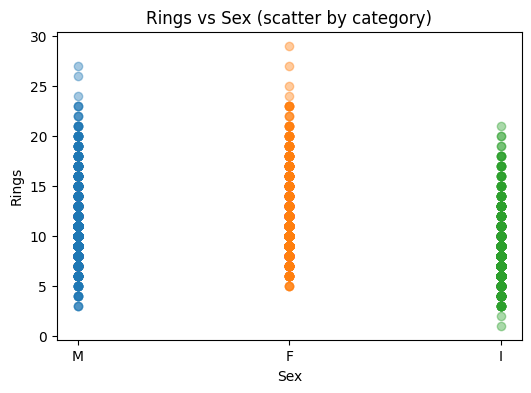

In [9]:
plt.figure(figsize=(6,4))

for sex in df["Sex"].unique():
    y_plot = df[df["Sex"] == sex]["Rings"]
    x_plot = [sex] * len(y_plot)
    plt.scatter(x_plot, y_plot, alpha=0.4)

plt.xlabel("Sex")
plt.ylabel("Rings")
plt.title("Rings vs Sex (scatter by category)")
plt.show()

The scatter plot shows substantial overlap in the distribution of rings across Male, Female, and Infant categories, with no clear monotonic trend or ordering, indicating that `Sex` is a nominal variable rather than an ordinal one.

### Mean Rings per Sex Category

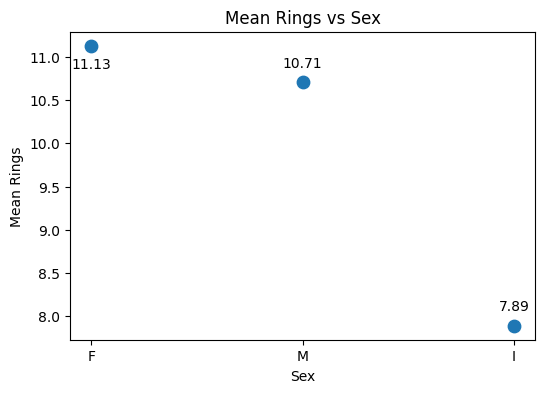

In [10]:
order = ["F", "M", "I"]

mean_rings = df.groupby("Sex")["Rings"].mean().reindex(order)

plt.figure(figsize=(6,4))
plt.scatter(mean_rings.index, mean_rings.values, s=80)

for sex, value in mean_rings.items():
    if sex == "F":
        plt.text(sex, value - 0.3, f"{value:.2f}", 
                 ha="center", va="bottom", fontsize=10)
    else:
        plt.text(sex, value + 0.3, f"{value:.2f}", 
                 ha="center", va="top", fontsize=10)

plt.xlabel("Sex")
plt.ylabel("Mean Rings")
plt.title("Mean Rings vs Sex")
plt.show()

---
## Data Preprocessing

### One-Hot Encoding for Categorical Variable (Sex)

Convert the categorical 'Sex' variable to binary dummy variables using one-hot encoding. We create `Sex_F` and `Sex_M` columns, with `I` (Infant) as the baseline.

In [11]:
sex_dummies = pd.get_dummies(df["Sex"], drop_first=False)

df["Sex_F"] = sex_dummies["F"].astype(int)
df["Sex_M"] = sex_dummies["M"].astype(int)

df = df.drop(columns=["Sex"])

df.head()

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Sex_F,Sex_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,0,1
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,0,1
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,1,0
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,0,1
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,0,0


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Length          4177 non-null   float64
 1   Diameter        4177 non-null   float64
 2   Height          4177 non-null   float64
 3   Whole_weight    4177 non-null   float64
 4   Shucked_weight  4177 non-null   float64
 5   Viscera_weight  4177 non-null   float64
 6   Shell_weight    4177 non-null   float64
 7   Rings           4177 non-null   int64  
 8   Sex_F           4177 non-null   int64  
 9   Sex_M           4177 non-null   int64  
dtypes: float64(7), int64(3)
memory usage: 326.5 KB


### Train-Validation-Test Split

Split the dataset into:
- **Training set**: 60%
- **Validation set**: 20%
- **Test set**: 20%

Also create the target variable as `Age = Rings + 1.5` and add bias term (intercept column) to the feature matrix.

In [13]:
np.random.seed(42)

y = df["Rings"].values + 1.5

X = df.drop(columns=["Rings"]).values

X = np.column_stack([np.ones(X.shape[0]), X])

n = X.shape[0]
indices = np.random.permutation(n)

train_size = int(0.6 * n)
val_size = int(0.2 * n)

train_idx = indices[:train_size]
val_idx = indices[train_size:train_size + val_size]
test_idx = indices[train_size + val_size:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val     = X[val_idx], y[val_idx]
X_test, y_test   = X[test_idx], y[test_idx]

print(f"Training set size: {len(X_train)}")
print(f"Validation set size: {len(X_val)}")
print(f"Test set size: {len(X_test)}")

Training set size: 2506
Validation set size: 835
Test set size: 836


### Feature Normalization (Standardization)

Standardize features using training set statistics (mean and standard deviation). Apply the same transformation to validation and test sets. The intercept column is left untouched.

In [14]:
X_mean = X_train[:, 1:].mean(axis=0)
X_std  = X_train[:, 1:].std(axis=0)
X_train[:, 1:] = (X_train[:, 1:] - X_mean) / X_std
X_val[:, 1:]   = (X_val[:, 1:] - X_mean) / X_std
X_test[:, 1:]  = (X_test[:, 1:] - X_mean) / X_std

print("Feature scaling complete using training set statistics.")

Feature scaling complete using training set statistics.


---
# Task 2(i): Multivariate Regression using QR Factorization (Closed-Form Solution)

## QR Decomposition Implementation

Implement QR decomposition from scratch using the Gram-Schmidt orthogonalization process. This is used to solve the normal equations for linear regression without using any library functions.

**Algorithm:**
- Uses unnormalized Gram-Schmidt process
- Includes numerical safety check for near-zero denominators
- Returns orthogonal matrix Q and upper triangular matrix R

In [15]:
def qr_decomposition(X):
    n, p = X.shape
    Q = np.zeros((n, p))
    R = np.zeros((p, p))

    for j in range(p):
        v = X[:, j].copy()
        for i in range(j):
            den = np.dot(Q[:, i], Q[:, i])
            if den < 1e-12:
                R[i, j] = 0.0
            else:
                R[i, j] = np.dot(Q[:, i], v) / den
            v = v - R[i, j] * Q[:, i]
        Q[:, j] = v
        R[j, j] = 1.0

    return Q, R

def back_substitution(R, z):
    p = R.shape[0]
    w = np.zeros(p)

    for i in reversed(range(p)):
        w[i] = z[i] - np.dot(R[i, i+1:], w[i+1:])

    return w

def delta_inverse(Q):
    norms_squared = np.sum(Q * Q, axis=0)
    return np.diag(1.0 / norms_squared)

### Linear Regression via QR Decomposition

Implement the closed-form solution for linear regression using QR decomposition:
$$\mathbf{w} = R^{-1} \Delta^{-1} Q^T \mathbf{y}$$

In [16]:
def linear_regression(X, y):
    Q, R = qr_decomposition(X)
    Delta_inv = delta_inverse(Q)

    rhs = Delta_inv @ (Q.T @ y)
    w = back_substitution(R, rhs)

    return w

def regression_metrics(y_true, y_pred):
    resid = y_true - y_pred
    sse = np.sum(resid ** 2)
    mse = np.mean(resid ** 2)
    rmse = np.sqrt(mse)
    r2 = 1 - sse / np.sum((y_true - y_true.mean()) ** 2)
    return sse, mse, rmse, r2

### Evaluate QR-based Linear Regression

**Training Protocol:**
1. Train on training set only
2. Evaluate on validation set
3. Retrain on training + validation set
4. Final evaluation on test set

In [17]:
w_qr_train = linear_regression(X_train, y_train)

print("Linear Regression via QR Decomposition")
print("-" * 50)

y_train_pred = X_train @ w_qr_train
_, _, rmse_train, r2_train = regression_metrics(y_train, y_train_pred)
print(f"Train RMSE: {rmse_train:.4f}")
print(f"Train R²: {r2_train:.4f}")

y_val_pred = X_val @ w_qr_train
_, _, rmse_val, r2_val = regression_metrics(y_val, y_val_pred)
print(f"Validation RMSE: {rmse_val:.4f}")
print(f"Validation R²: {r2_val:.4f}")

Linear Regression via QR Decomposition
--------------------------------------------------
Train RMSE: 2.2123
Train R²: 0.5334
Validation RMSE: 2.3585
Validation R²: 0.5329


### Final Model: Retrain on Train + Validation, Evaluate on Test

In [18]:
X_fit = np.vstack([X_train, X_val])
y_fit = np.concatenate([y_train, y_val])
w_hat = linear_regression(X_fit, y_fit)

print(f"Final QR weights (trained on TRAIN+VAL): {w_hat}")

y_test_pred = X_test @ w_hat
sse_qr, mse_qr, rmse_qr, r2_qr = regression_metrics(y_test, y_test_pred)

print(f"\nTest RMSE: {rmse_qr:.4f}")
print(f"Test R²: {r2_qr:.4f}")

Final QR weights (trained on TRAIN+VAL): [11.40374484 -0.05538611  1.14343219  0.37963411  4.25682787 -4.28068455
 -1.14325159  1.2841604   0.38060353  0.44381044]

Test RMSE: 2.0126
Test R²: 0.5258


**QR Decomposition Results:**

| Metric | Train | Validation | Test |
|--------|-------|------------|------|
| RMSE |2.2123|2.3585|2.0126|
| R² |0.5334|0.5329|0.5258|

---
# Task 2(ii): SGD for Linear Regression

## Stochastic Gradient Descent Implementation

Implement Stochastic Gradient Descent (SGD) for linear regression from scratch.

**Algorithm:**
- For each epoch, shuffle the data
- Update weights for each sample: $\mathbf{w} = \mathbf{w} + \eta \cdot (y_k - \mathbf{x}_k^T \mathbf{w}) \cdot \mathbf{x}_k$
- Use loss-based convergence criterion (more robust than parameter difference)

In [19]:
def sgd_linear_regression(X, y, eta=1e-4, epochs=1000, tol=1e-6):
    n, p = X.shape
    w = np.zeros(p)
    prev_loss = np.inf

    for epoch in range(epochs):
        indices = np.random.permutation(n)
        for k in indices:
            xk = X[k]
            yk = y[k]
            grad_xk = yk - np.dot(xk, w)
            w = w + eta * grad_xk * xk
        loss = np.mean((y - X @ w) ** 2)
        if abs(prev_loss - loss) < tol:
            break
        prev_loss = loss

    return w

### Hyperparameter Tuning: Learning Rate (η)

Perform grid search over learning rates to find the optimal η that minimizes validation RMSE.

In [20]:
eta_list = np.logspace(
    np.log10(4e-3),
    np.log10(4.8e-3),
    10
)

val_results = []

for eta in eta_list:
    w_eta = sgd_linear_regression(
        X_train,
        y_train,
        eta=eta,
        epochs=100
    )

    y_val_pred = X_val @ w_eta
    sse, mse, rmse, _ = regression_metrics(y_val, y_val_pred)
    val_results.append((eta, sse, mse, rmse))

best_eta, best_sse, best_mse, best_rmse = min(
    val_results,
    key=lambda x: x[3]
)

print("Validation results (SGD)")
print("-" * 50)
print("eta\t\tSSE\t\tMSE\t\tRMSE")

for eta, sse, mse, rmse in val_results:
    print(f"{eta:.4e}\t{sse:.4f}\t{mse:.4f}\t\t{rmse:.4f}")

print("\nBest eta based on validation RMSE:")
print(f"eta = {best_eta}, RMSE = {best_rmse:.4f}")

Validation results (SGD)
--------------------------------------------------
eta		SSE		MSE		RMSE
4.0000e-03	4737.4367	5.6736		2.3819
4.0819e-03	4659.8823	5.5807		2.3623
4.1654e-03	4710.6371	5.6415		2.3752
4.2506e-03	4764.5273	5.7060		2.3887
4.3376e-03	4800.2966	5.7489		2.3977
4.4264e-03	4723.7904	5.6572		2.3785
4.5170e-03	4797.1399	5.7451		2.3969
4.6094e-03	4711.7302	5.6428		2.3755
4.7037e-03	4562.6419	5.4642		2.3376
4.8000e-03	4596.5277	5.5048		2.3462

Best eta based on validation RMSE:
eta = 0.004703740142048427, RMSE = 2.3376


### Final SGD Model: Train on Train+Val, Evaluate on Test

In [21]:
X_fit = np.vstack([X_train, X_val])
y_fit = np.concatenate([y_train, y_val])

w_sgd_final = sgd_linear_regression(
    X_fit,
    y_fit,
    eta=best_eta,
    epochs=1000
)

print(f"Final SGD weights: {w_sgd_final}")

y_test_pred = X_test @ w_sgd_final

sse_sgd, mse_sgd, rmse_sgd, r2_sgd = regression_metrics(y_test, y_test_pred)

print("\nFinal test performance (SGD)")
print("-" * 45)
print(f"SSE  : {sse_sgd:.4f}")
print(f"MSE  : {mse_sgd:.4f}")
print(f"RMSE : {rmse_sgd:.4f}")
print(f"R²   : {r2_sgd:.4f}")

Final SGD weights: [11.53351403  0.15263329  1.39422216 -0.32481668  4.43791402 -4.2375721
 -1.01828159  1.64397291  0.41889299  0.49551327]

Final test performance (SGD)
---------------------------------------------
SSE  : 3823.8584
MSE  : 4.5740
RMSE : 2.1387
R²   : 0.4645


**SGD Linear Regression Results:**

| Metric | Value |
|--------|-------|
| Best η |0.0047|
| Test SSE |3823.86|
| Test MSE |4.5740|
| Test RMSE |2.1387|
| Test R² |0.4645|

---
# Task 2(iii): SGD with Ridge Regression (L2 Regularization)

## SGD Ridge Regression Implementation

Implement SGD with L2 regularization (Ridge Regression).

**Update Rule:**
$$\mathbf{w} = \mathbf{w} + \eta \cdot ((y_k - \mathbf{x}_k^T \mathbf{w}) \cdot \mathbf{x}_k - \lambda \cdot \mathbf{w})$$

Note: The intercept (bias) term is **not** regularized.

In [22]:
def sgd_ridge_regression(X, y, eta=4.5e-3, lam=1e-2,
                         epochs=1000, tol=1e-6):
    n, p = X.shape
    w = np.zeros(p)
    prev_loss = np.inf

    for epoch in range(epochs):
        indices = np.random.permutation(n)
        for k in indices:
            xk = X[k]
            yk = y[k]
            error = yk - np.dot(xk, w)
            grad_penalty = lam * np.r_[0, w[1:]]
            w = w + eta * (error * xk - grad_penalty)
        loss = np.mean((y - X @ w) ** 2) + lam * np.sum(w[1:] ** 2)
        if abs(prev_loss - loss) < tol:
            break
        prev_loss = loss

    return w

### Grid Search for Ridge Hyperparameters (η, λ)

Perform 2D grid search over learning rate (η) and regularization strength (λ) to find optimal hyperparameters.

In [23]:
eta_grid = np.logspace(
    np.log10(4.2e-3),
    np.log10(5e-3),
    5
)
lambda_grid = np.logspace(-3, 1, 5)

grid_results = []

total_iters = len(eta_grid) * len(lambda_grid)

with tqdm(total=total_iters, desc="Grid search (eta, lambda)") as pbar:
    for eta in eta_grid:
        for lam in lambda_grid:

            w = sgd_ridge_regression(
                X_train,
                y_train,
                eta=eta,
                lam=lam,
                epochs=100
            )

            y_val_pred = X_val @ w
            _, mse, rmse, _ = regression_metrics(y_val, y_val_pred)
            grid_results.append((eta, lam, mse, rmse))
            pbar.update(1)

print("Validation results (SGD Ridge)")
print("-" * 60)
print("eta\t\tlambda\t\tMSE\t\tRMSE")

for eta, lam, mse, rmse in grid_results:
    print(f"{eta:.1e}\t\t{lam:.1e}\t\t{mse:.4f}\t\t{rmse:.6f}")

best_eta_ridge, best_lam_ridge, best_mse_ridge, best_rmse_ridge = min(
    grid_results,
    key=lambda x: x[3]
)
print("-" * 60)
print("\nBest hyperparameters:")
print(f"eta    = {best_eta_ridge}")
print(f"lambda = {best_lam_ridge}")
print(f"MSE    = {best_mse_ridge}")
print(f"RMSE   = {best_rmse_ridge}")

Grid search (eta, lambda): 100%|██████████| 25/25 [00:58<00:00,  2.35s/it]

Validation results (SGD Ridge)
------------------------------------------------------------
eta		lambda		MSE		RMSE
4.2e-03		1.0e-03		5.5533		2.356535
4.2e-03		1.0e-02		5.6347		2.373750
4.2e-03		1.0e-01		6.9464		2.635604
4.2e-03		1.0e+00		7.9703		2.823175
4.2e-03		1.0e+01		9.3188		3.052668
4.4e-03		1.0e-03		5.7400		2.395821
4.4e-03		1.0e-02		5.8420		2.417027
4.4e-03		1.0e-01		6.3674		2.523374
4.4e-03		1.0e+00		7.4023		2.720719
4.4e-03		1.0e+01		9.2814		3.046534
4.6e-03		1.0e-03		5.7290		2.393540
4.6e-03		1.0e-02		6.0600		2.461707
4.6e-03		1.0e-01		6.3817		2.526208
4.6e-03		1.0e+00		7.7376		2.781662
4.6e-03		1.0e+01		10.3182		3.212189
4.8e-03		1.0e-03		5.6875		2.384852
4.8e-03		1.0e-02		5.8788		2.424624
4.8e-03		1.0e-01		6.3874		2.527332
4.8e-03		1.0e+00		8.0541		2.837968
4.8e-03		1.0e+01		8.6796		2.946117
5.0e-03		1.0e-03		5.8344		2.415451
5.0e-03		1.0e-02		5.6050		2.367479
5.0e-03		1.0e-01		6.3976		2.529345
5.0e-03		1.0e+00		7.3026		2.702333
5.0e-03		1.0e+01		9.6767		3.110733
---------

### Final Ridge Model: Train on Train+Val, Evaluate on Test

In [24]:
X_fit = np.vstack([X_train, X_val])
y_fit = np.concatenate([y_train, y_val])

w_ridge_final = sgd_ridge_regression(
    X_fit,
    y_fit,
    eta=best_eta_ridge,
    lam=best_lam_ridge,
    epochs=1000
)
print(f"Final SGD Ridge weights: {w_ridge_final}")

y_test_pred = X_test @ w_ridge_final

sse_ridge, mse_ridge, rmse_ridge, r2_ridge = regression_metrics(y_test, y_test_pred)

print("\nFinal test performance (Ridge + SGD)")
print("-" * 50)
print(f"lambda : {best_lam_ridge}")
print(f"SSE    : {sse_ridge:.4f}")
print(f"MSE    : {mse_ridge:.4f}")
print(f"RMSE   : {rmse_ridge:.8f}")
print(f"R²     : {r2_ridge:.4f}")

Final SGD Ridge weights: [11.35980985  0.12665141  1.31046164 -0.2240956   3.77224926 -4.03938199
 -0.93066722  1.58058773  0.22619498  0.57260432]

Final test performance (Ridge + SGD)
--------------------------------------------------
lambda : 0.001
SSE    : 3601.5701
MSE    : 4.3081
RMSE   : 2.07559588
R²     : 0.4957


**SGD Ridge Regression Results:**

| Metric | Value |
|--------|-------|
| Best η |0.0042|
| Best λ |0.001|
| Test SSE |3601.57|
| Test MSE |4.3081|
| Test RMSE |2.075|
| Test R² |0.4957|

---
# Task 2(iv): SGD with LASSO Regression (L1 Regularization)

## SGD LASSO Regression Implementation

Implement SGD with L1 regularization (LASSO Regression) using subgradient descent.

**Update Rule:**
$$\mathbf{w} = \mathbf{w} + \eta \cdot ((y_k - \mathbf{x}_k^T \mathbf{w}) \cdot \mathbf{x}_k - \lambda \cdot \text{sign}(\mathbf{w}))$$

Note: The intercept (bias) term is **not** regularized. LASSO promotes sparsity in the weight vector.

In [25]:
def sgd_lasso_regression(X, y, eta=1e-4, lam=1e-3, epochs=1000, tol=1e-6):
    n, p = X.shape
    w = np.zeros(p)
    prev_loss = np.inf

    for epoch in range(epochs):
        indices = np.random.permutation(n)

        for k in indices:
            xk = X[k]
            yk = y[k]
            error = yk - np.dot(xk, w)
            w = w + eta * error * xk
            w[1:] = np.sign(w[1:]) * np.maximum(np.abs(w[1:]) - eta * lam, 0.0)
        loss = np.mean((y - X @ w) ** 2) + lam * np.sum(np.abs(w[1:]))
        if abs(prev_loss - loss) < tol:
            break
        prev_loss = loss

    return w

### Grid Search for LASSO Hyperparameters (η, λ)

Perform 2D grid search over learning rate (η) and regularization strength (λ) for LASSO regression.

In [26]:
eta_grid = np.logspace(-4, -2, 5)
lambda_grid = np.logspace(-4, 0, 5)

lasso_results = []

with tqdm(total=len(eta_grid)*len(lambda_grid),
          desc="Grid search (LASSO)") as pbar:

    for eta in eta_grid:
        for lam in lambda_grid:

            w = sgd_lasso_regression(
                X_train,
                y_train,
                eta=eta,
                lam=lam,
                epochs=100
            )

            y_val_pred = X_val @ w
            _, mse, rmse, _ = regression_metrics(y_val, y_val_pred)

            lasso_results.append((eta, lam, mse, rmse))
            pbar.update(1)

best_eta_lasso, best_lam_lasso, best_mse_lasso, best_rmse_lasso = min(
    lasso_results,
    key=lambda x: x[3]
)
print("Validation results (SGD LASSO)")
print("-" * 60)
print(f"Best eta    = {best_eta_lasso}")
print(f"Best lambda = {best_lam_lasso}")
print(f"Min RMSE    = {best_rmse_lasso:.4f}")

Grid search (LASSO): 100%|██████████| 25/25 [00:42<00:00,  1.71s/it]

Validation results (SGD LASSO)
------------------------------------------------------------
Best eta    = 0.01
Best lambda = 0.01
Min RMSE    = 2.3487


### Final LASSO Model: Train on Train+Val, Evaluate on Test

In [27]:
X_fit = np.vstack([X_train, X_val])
y_fit = np.concatenate([y_train, y_val])

w_lasso_final = sgd_lasso_regression(
    X_fit,
    y_fit,
    eta=best_eta_lasso,
    lam=best_lam_lasso,
    epochs=1000
)

print(f"Final SGD LASSO weights: {w_lasso_final}")

y_test_pred = X_test @ w_lasso_final

sse_lasso, mse_lasso, rmse_lasso, r2_lasso = regression_metrics(y_test, y_test_pred)

print("\nFinal test performance (LASSO + SGD)")
print("-" * 50)
print(f"lambda : {best_lam_lasso}")
print(f"SSE    : {sse_lasso:.4f}")
print(f"MSE    : {mse_lasso:.4f}")
print(f"RMSE   : {rmse_lasso:.8f}")
print(f"R²     : {r2_lasso:.4f}")

num_zero_weights = np.sum(np.abs(w_lasso_final[1:]) < 1e-6)
print(f"\nNumber of zero (sparse) weights: {num_zero_weights}")

Final SGD LASSO weights: [11.31885565  0.28244624  1.15279225 -1.1069179   3.09020013 -3.66298265
 -0.41680793  1.99696599  0.5294671   0.28994991]

Final test performance (LASSO + SGD)
--------------------------------------------------
lambda : 0.01
SSE    : 3869.0105
MSE    : 4.6280
RMSE   : 2.15127939
R²     : 0.4582

Number of zero (sparse) weights: 0


**SGD LASSO Regression Results:**

| Metric | Value |
|--------|-------|
| Best η |0.01|
| Best λ |0.01|
| Test SSE |3869.01|
| Test MSE |4.628|
| Test RMSE |2.1513|
| Test R² |0.4582|
| Zero Weights |0|

---
## Task 2(v): Sklearn Linear Regression (Baseline)

Using sklearn's `LinearRegression` as a baseline comparison for our custom implementations.

In [28]:
from sklearn.linear_model import LinearRegression

sklearn_model = LinearRegression(fit_intercept=False, copy_X=True, n_jobs=-1)
sklearn_model.fit(X_train, y_train)

y_val_pred_sklearn = sklearn_model.predict(X_val)
sse_val_sklearn, mse_val_sklearn, rmse_val_sklearn, r2_val_sklearn = regression_metrics(y_val, y_val_pred_sklearn)

print("Sklearn Linear Regression - Validation Performance:")
print(f"  RMSE: {rmse_val_sklearn:.4f}")
print(f"  R²:   {r2_val_sklearn:.4f}")
print(f"  MSE:  {mse_val_sklearn:.4f}")

Sklearn Linear Regression - Validation Performance:
  RMSE: 2.3585
  R²:   0.5329
  MSE:  5.5627


### Retrain on TRAIN+VAL and Evaluate on TEST

In [29]:
X_fit = np.vstack([X_train, X_val])
y_fit = np.concatenate([y_train, y_val])

sklearn_model_final = LinearRegression(fit_intercept=False, copy_X=True, n_jobs=-1)
sklearn_model_final.fit(X_fit, y_fit)

y_test_pred_sklearn = sklearn_model_final.predict(X_test)
sse_sklearn, mse_sklearn, rmse_sklearn, r2_sklearn = regression_metrics(y_test, y_test_pred_sklearn)

print("SKLEARN LINEAR REGRESSION - TEST RESULTS")
print(f"Test SSE:  {sse_sklearn:.4f}")
print(f"Test MSE:  {mse_sklearn:.4f}")
print(f"Test RMSE: {rmse_sklearn:.4f}")
print(f"Test R²:   {r2_sklearn:.4f}")

SKLEARN LINEAR REGRESSION - TEST RESULTS
Test SSE:  3386.2010
Test MSE:  4.0505
Test RMSE: 2.0126
Test R²:   0.5258


**Sklearn Linear Regression Results:**

| Metric | Value |
|--------|-------|
| Test SSE |3386.20|
| Test MSE |4.0505|
| Test RMSE |2.0126|
| Test R² |0.5258|

---
# Comparison of All Models

## Summary Table

Compare the performance of all five regression methods on the test set.

In [30]:
print("=" * 70)
print("COMPARISON OF ALL REGRESSION MODELS")
print("=" * 70)
print(f"{'Model':<25} {'RMSE':>12} {'R²':>12} {'MSE':>12}")
print("-" * 70)
print(f"{'QR Decomposition':<25} {rmse_qr:>12.4f} {r2_qr:>12.4f} {mse_qr:>12.4f}")
print(f"{'SGD Linear':<25} {rmse_sgd:>12.4f} {r2_sgd:>12.4f} {mse_sgd:>12.4f}")
print(f"{'SGD Ridge':<25} {rmse_ridge:>12.4f} {r2_ridge:>12.4f} {mse_ridge:>12.4f}")
print(f"{'SGD Lasso':<25} {rmse_lasso:>12.4f} {r2_lasso:>12.4f} {mse_lasso:>12.4f}")
print(f"{'SKLEARN LINEAR':<25} {rmse_sklearn:>12.4f} {r2_sklearn:>12.4f} {mse_sklearn:>12.4f}")
print("=" * 70)

COMPARISON OF ALL REGRESSION MODELS
Model                             RMSE           R²          MSE
----------------------------------------------------------------------
QR Decomposition                2.0126       0.5258       4.0505
SGD Linear                      2.1387       0.4645       4.5740
SGD Ridge                       2.0756       0.4957       4.3081
SGD Lasso                       2.1513       0.4582       4.6280
SKLEARN LINEAR                  2.0126       0.5258       4.0505


## Conclusion

On the test set, the closed-form solution (QR) and `sklearn` LinearRegression perform best; SGD variants are slightly worse and depend more on tuning/regularization.

**Test-set performance (lower RMSE is better):**
- **QR Decomposition:** RMSE **2.0126**, R² **0.5258**
- **Sklearn Linear Regression:** RMSE **2.0126**, R² **0.5258**
- **SGD Ridge (L2):** RMSE **2.0756**, R² **0.4957**
- **SGD Linear:** RMSE **2.1387**, R² **0.4645**
- **SGD LASSO (L1):** RMSE **2.1513**, R² **0.4582**

**Why this happens (brief):**
- **QR Decomposition:** directly solves least squares → best linear fit for these features.
- **Sklearn Linear Regression:** solves the same objective as QR here → same result.
- **SGD methods:** approximate the optimum → can stop short depending on learning rate/epochs.
- **Ridge (L2):** shrinks weights → often improves generalization a bit.
- **LASSO (L1):** can over-shrink with a small feature set → mild underfitting here.

**Overall:** R² ≈ **0.53** suggests a simple linear model misses nonlinear effects/interactions. QR and `sklearn` match because they optimize the same least-squares objective (bias column used with `fit_intercept=False`).